# Training Neural Networks with PyTorch (`nn` Module)

This notebook demonstrates how to transition from building models from scratch to leveraging PyTorch's powerful `nn` and `optim` modules. It is a continuation of our previous work on manual linear regression and autograd.

In this notebook, we:
1. Prepare and split our temperature conversion data into training and validation sets.
2. Implement a linear model using `nn.Linear` and optimize it using `optim.SGD`.
3. Explore multi-layer non-linear neural networks using `nn.Sequential` with `nn.Tanh` activations.
4. Visualize our model's predictions against the original dataset.

In [ ]:
%matplotlib inline
import numpy as np
import torch
import torch.optim as optim

torch.set_printoptions(edgeitems=2, linewidth=75)

## 1. Dataset Preparation

We start by importing our toy dataset (Celsius `t_c` vs Unknown physical unit `t_u` which is close to Fahrenheit) and reshaping the tensors to have a batch dimension.

In [ ]:
t_c = [0.5,  14.0, 15.0, 28.0, 11.0,  8.0,  3.0, -4.0,  6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c).unsqueeze(1) # <1>
t_u = torch.tensor(t_u).unsqueeze(1) # <1>

t_u.shape

torch.Size([11, 1])

### Shuffling and Splitting Data

To ensure proper generalization, we shuffle our indices and split the dataset into an **80% training set** and a **20% validation set**.

In [ ]:
n_samples = t_u.shape[0]
n_val = int(0.2 * n_samples)

shuffled_indices = torch.randperm(n_samples)

train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

train_indices, val_indices

(tensor([ 2,  9,  0,  6,  8,  5,  4, 10,  3]), tensor([7, 1]))

### Data Normalization

We normalize our input features `t_u` by multiplying them by `0.1` to prevent gradient explosion issues during optimization.

In [ ]:
t_u_train = t_u[train_indices]
t_c_train = t_c[train_indices]

t_u_val = t_u[val_indices]
t_c_val = t_c[val_indices]

t_un_train = 0.1 * t_u_train
t_un_val = 0.1 * t_u_val

## 2. Linear Models with `torch.nn`

Instead of writing raw weight matrices and bias vectors, we use PyTorch's high-level `nn.Linear` module to instantiate a linear layer with 1 input and 1 output dimension.

In [ ]:
import torch.nn as nn

linear_model = nn.Linear(1,1)
linear_model(t_un_val)

tensor([[1.5475],
        [4.3181]], grad_fn=<AddmmBackward0>)

In [ ]:
linear_model.weight, linear_model.bias

(Parameter containing:
 tensor([[0.8125]], requires_grad=True),
 Parameter containing:
 tensor([-0.2238], requires_grad=True))

### Testing Model Output Structure

We pass a synthetic batch of ones through our model to verify that output shapes match expectations.

In [ ]:
x = torch.ones(10,1)
linear_model(x)

tensor([[0.5887],
        [0.5887],
        [0.5887],
        [0.5887],
        [0.5887],
        [0.5887],
        [0.5887],
        [0.5887],
        [0.5887],
        [0.5887]], grad_fn=<AddmmBackward0>)

### Training with Optimizers

We instantiate our PyTorch Stochastic Gradient Descent (`optim.SGD`) optimizer, passing the parameters of our newly created model.

In [ ]:
linear_model = nn.Linear(1,1)
optimizer = optim.SGD(linear_model.parameters(),lr = 1e-2)

In [ ]:
linear_model.parameters()

<generator object Module.parameters at 0x000001ECDB5E92A0>

In [ ]:
list(linear_model.parameters())

[Parameter containing:
 tensor([[0.1771]], requires_grad=True),
 Parameter containing:
 tensor([-0.0960], requires_grad=True)]

## 3. General Training Loop

Below is a standardized training loop using PyTorch loss functions, gradient zeroing, backward passes, and step optimizations.

In [ ]:
def training_loop(n_epochs, optimizer, model, loss_fn,
                  t_u_train, t_u_val, t_c_train, t_c_val):

    for epoch in range(1, n_epochs +1):
        t_p_train = model(t_u_train)
        loss_train = loss_fn(t_p_train, t_c_train)

        t_p_val = model(t_u_val)
        loss_val = loss_fn(t_p_val, t_c_val)

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        if epoch == 1 or epoch % 1000 == 0:
            print(f"Epoch {epoch}, Training loss {loss_train.item():.4f},"
                  f" Validation loss {loss_val.item():.4f}")


### Executing the Linear Model Training

In [ ]:
linear_model = nn.Linear(1,1)
optimizer =  optim.SGD(linear_model.parameters(), lr = 1e-2)

training_loop(
    n_epochs = 3000,
    optimizer=optimizer,
    model = linear_model,
    loss_fn= nn.MSELoss(),
    t_u_train= t_un_train,
    t_u_val= t_un_val,
    t_c_train= t_c_train,
    t_c_val= t_c_val
)

print()
print(linear_model.weight)
print(linear_model.bias)

Epoch 1, Training loss 405.3197, Validation loss 202.2822
Epoch 1000, Training loss 4.8051, Validation loss 1.1201
Epoch 2000, Training loss 3.0059, Validation loss 2.8533
Epoch 3000, Training loss 2.8569, Validation loss 4.4851

Parameter containing:
tensor([[5.5668]], requires_grad=True)
Parameter containing:
tensor([-18.6872], requires_grad=True)


## 4. Multi-Layer Networks with `nn.Sequential`

To move beyond a simple straight-line fit, we can stack layers using `nn.Sequential` and introduce a non-linear activation function, `nn.Tanh`.

In [ ]:
seq_model = nn.Sequential(
    nn.Linear(1,13),
    nn.Tanh(),
    nn.Linear(13,1)
)

seq_model

Sequential(
  (0): Linear(in_features=1, out_features=13, bias=True)
  (1): Tanh()
  (2): Linear(in_features=13, out_features=1, bias=True)
)

In [ ]:
[param.shape for param in seq_model.parameters()]

[torch.Size([13, 1]), torch.Size([13]), torch.Size([1, 13]), torch.Size([1])]

### Named Layers with `OrderedDict`

For better readability and easier layer access, we can label our sub-modules using `collections.OrderedDict`.

In [ ]:
from collections import OrderedDict

seq_model = nn.Sequential(OrderedDict([
    ('hidden_linear', nn.Linear(1, 8)),
    ('hidden_activation', nn.Tanh()),
    ('output_linear', nn.Linear(8, 1))
]))

seq_model

Sequential(
  (hidden_linear): Linear(in_features=1, out_features=8, bias=True)
  (hidden_activation): Tanh()
  (output_linear): Linear(in_features=8, out_features=1, bias=True)
)

In [ ]:
for name, param in seq_model.named_parameters():
    print(name, param.shape)

hidden_linear.weight torch.Size([8, 1])
hidden_linear.bias torch.Size([8])
output_linear.weight torch.Size([1, 8])
output_linear.bias torch.Size([1])


In [ ]:
seq_model.output_linear.bias

Parameter containing:
tensor([0.2548], requires_grad=True)

### Training the Non-Linear Neural Network

In [ ]:
optimizer = optim.SGD(seq_model.parameters(), lr=1e-3) # <1>

training_loop(
    n_epochs = 5000,
    optimizer = optimizer,
    model = seq_model,
    loss_fn = nn.MSELoss(),
    t_u_train = t_un_train,
    t_u_val = t_un_val,
    t_c_train = t_c_train,
    t_c_val = t_c_val)

print('output', seq_model(t_un_val))
print('answer', t_c_val)
print('hidden', seq_model.hidden_linear.weight.grad)

Epoch 1, Training loss 213.0118, Validation loss 109.9448
Epoch 1000, Training loss 6.6783, Validation loss 2.6763
Epoch 2000, Training loss 6.2637, Validation loss 0.1368
Epoch 3000, Training loss 2.9861, Validation loss 0.7745
Epoch 4000, Training loss 1.8942, Validation loss 3.0330
Epoch 5000, Training loss 1.5488, Validation loss 4.8200
output tensor([[-2.0041],
        [11.0534]], grad_fn=<AddmmBackward0>)
answer tensor([[-4.],
        [14.]])
hidden tensor([[ 7.5332e+00],
        [-8.1416e+00],
        [-1.7368e-03],
        [ 8.3873e+00],
        [ 1.5745e-02],
        [-8.1426e+00],
        [-2.8179e+00],
        [-5.7399e-03]])


## 5. Visualizing Model Predictions

Let's plot the non-linear regression curve generated by our sequential model against the actual data points.

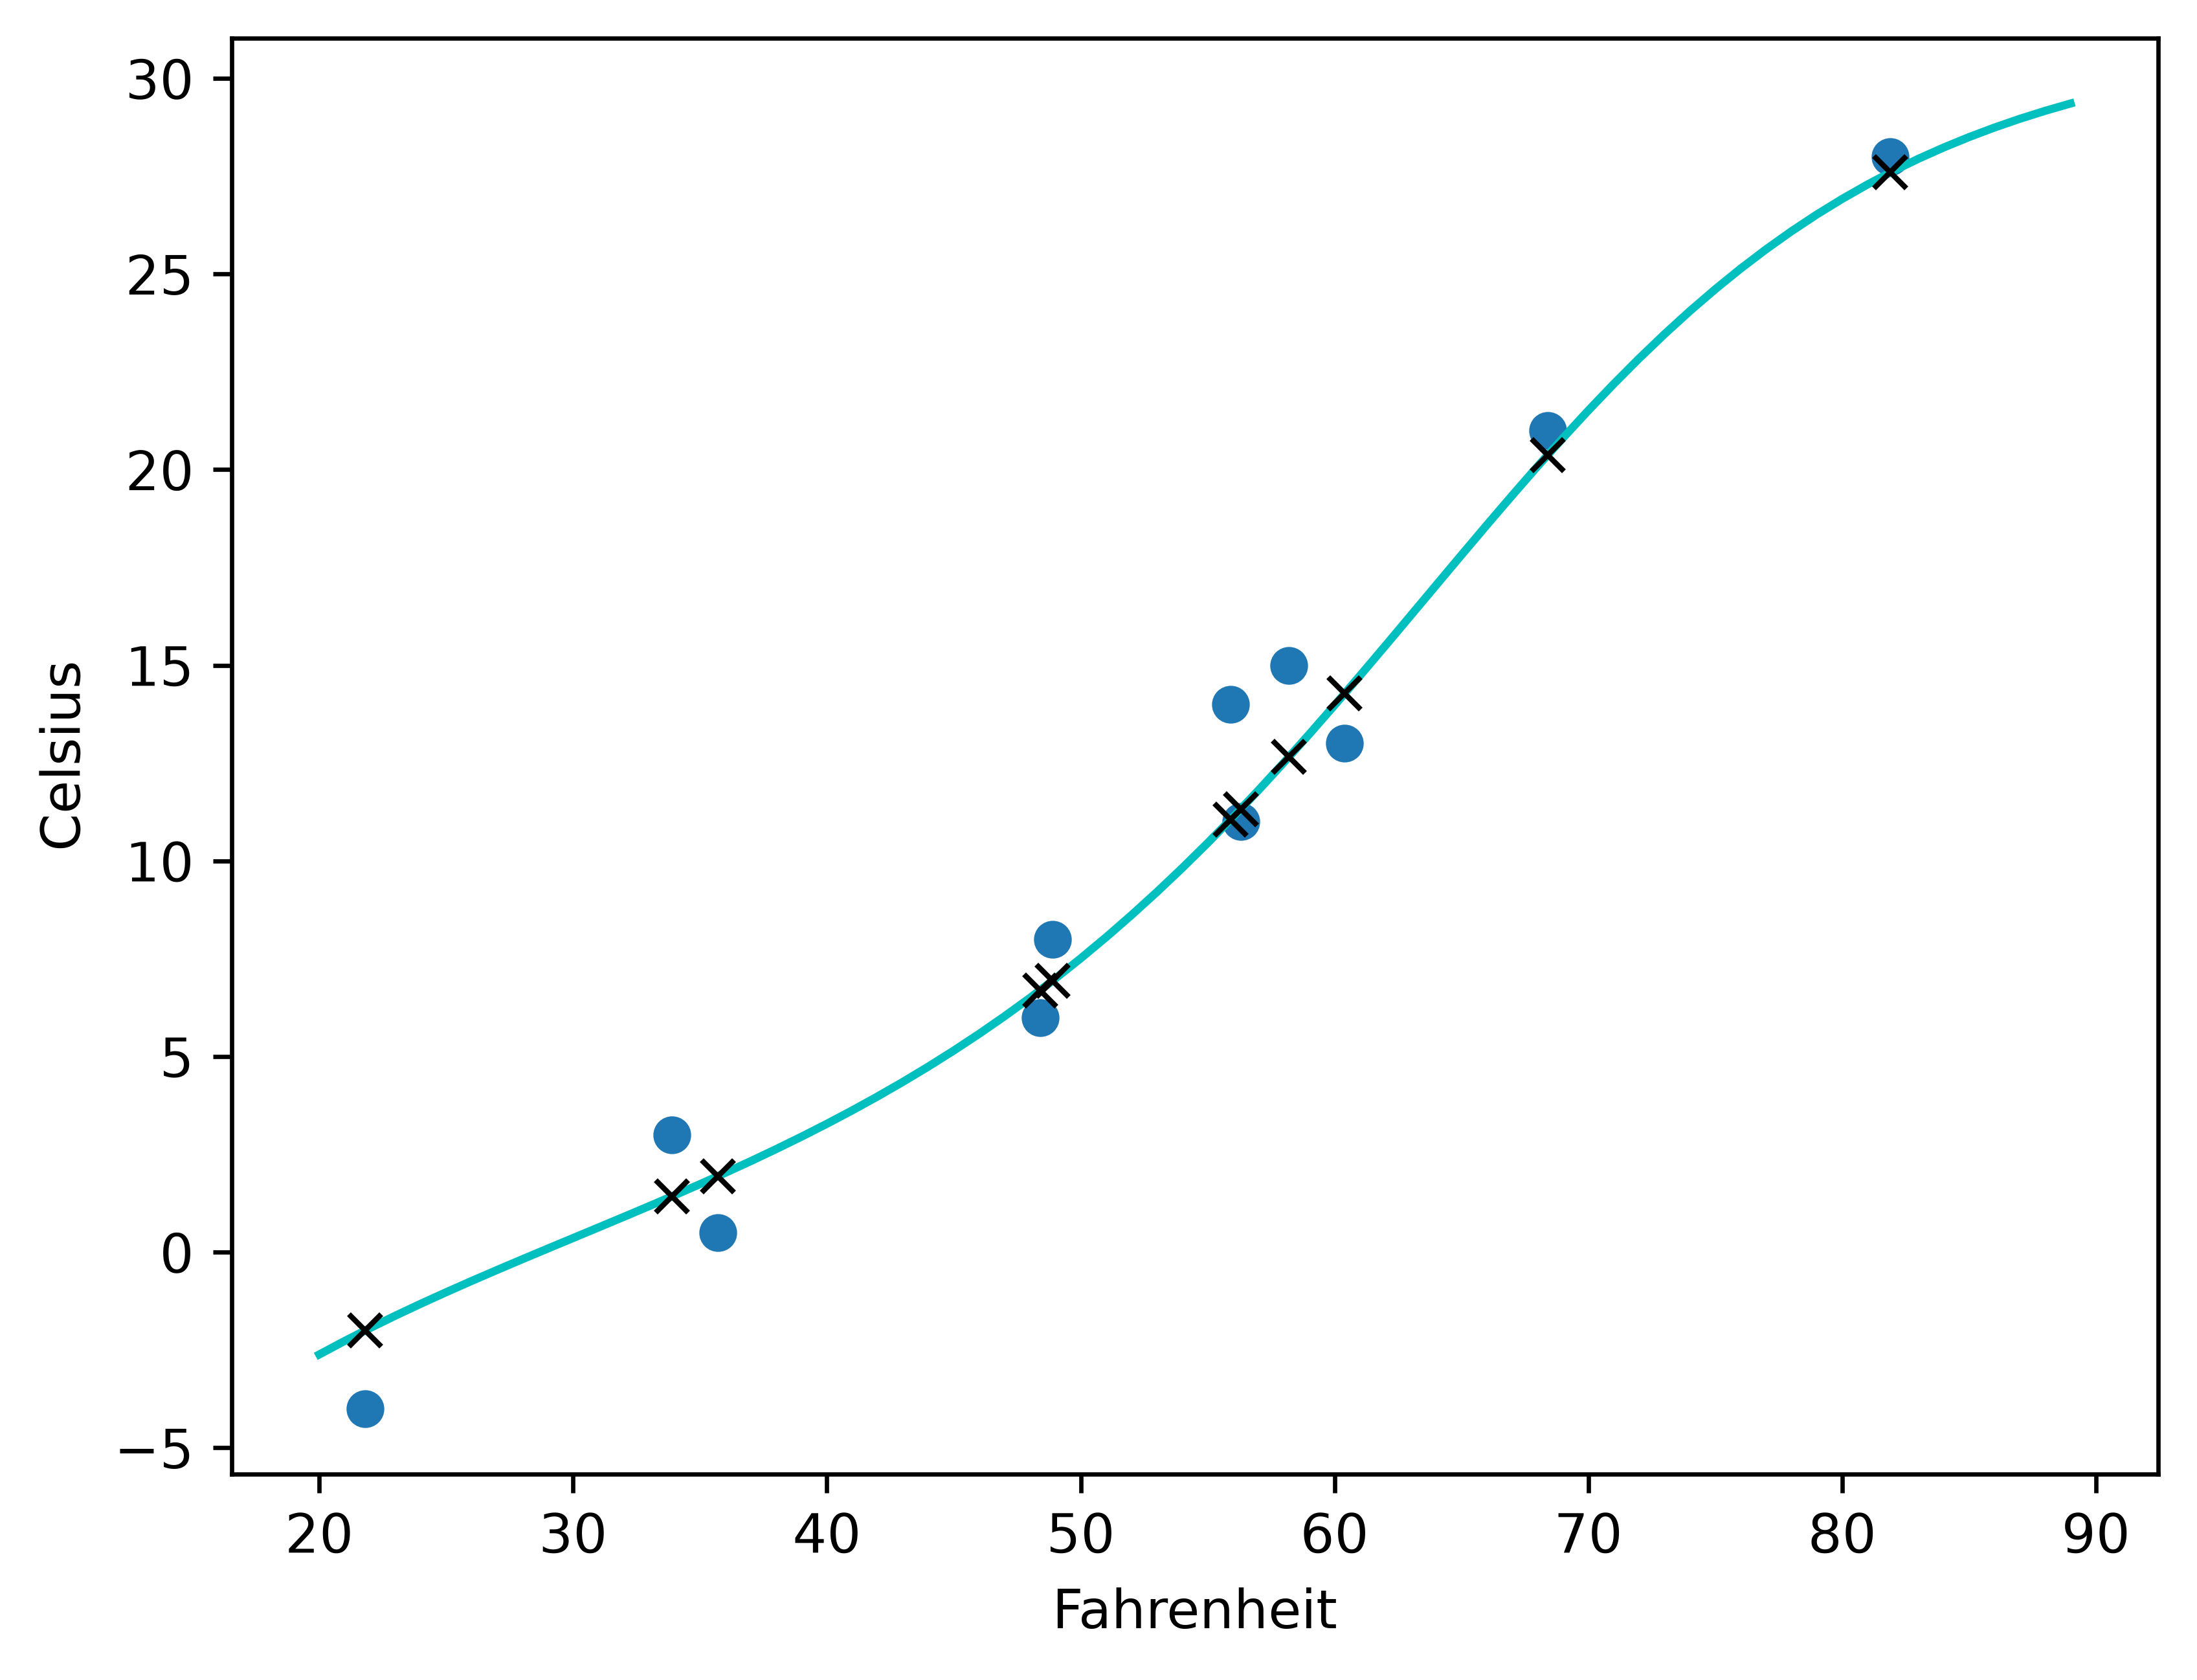

In [ ]:
from matplotlib import pyplot as plt

t_range = torch.arange(20., 90.).unsqueeze(1)

fig = plt.figure(dpi=600)
plt.xlabel("Fahrenheit")
plt.ylabel("Celsius")
plt.plot(t_u.numpy(), t_c.numpy(), 'o')
plt.plot(t_range.numpy(), seq_model(0.1 * t_range).detach().numpy(), 'c-')
plt.plot(t_u.numpy(), seq_model(0.1 * t_u).detach().numpy(), 'kx')

